# Notebook 08 — Giải đấu Round-Robin 7 Cấp độ AI, Độ đo Thống kê & Ablation (Mục 3.5)

Notebook này là **nơi thực thi trực tiếp toàn bộ giải đấu đối kháng** cho đề tài **Caro 11×11 (Free Gomoku, thắng khi đạt $\ge 5$ quân liên tiếp)** — chỉ cần mở Notebook này và bấm **Run All** để chạy trọn vẹn mọi cặp đấu, lưu log từng cặp, tính thống kê và sinh hình báo cáo theo **Mục 3.5** (*TTNTNC*) và sách *AlphaGo Simplified* (Mark Liu, 2025):

| Yêu cầu Mục 3.5 / Sách Mark Liu | Triển khai trực tiếp trong Notebook 08 | Đầu ra lưu trữ |
|---|---|---|
| **Round-Robin đầy đủ** giữa mọi tác tử | 7 cấp độ (`L1_Random` .. `L7_AlphaGo`) $\Rightarrow \binom{7}{2} = 21$ cặp đấu | `results/tables/tournament/<mode>/` |
| **$\ge 100$ ván/cặp (khuyến nghị 200)**, cân bằng 50/50 X-O | Mặc định `RUN_MODE = "official_100"` (100 ván/cặp); đổi 1 dòng sang `"recommended_200"` (200 ván/cặp) hoặc `"quick"` (4 ván kiểm thử); ghép cặp đối xứng 20 khai cuộc | Mỗi cặp lưu riêng 1 file `.jsonl` + tự động `RESUME = True` |
| **Chạy nhanh đa nhân ngay trên Notebook** | Tự động dùng `ProcessPoolExecutor` (`NUM_WORKERS = recommended_workers()`), theo dõi tiến độ & ETA từng cặp đấu | Tăng tốc ~4–7× so với đơn nhân |
| **Đa seed** cho tác tử ngẫu nhiên / phá hòa | `SEEDS = (42, 102, 202, 302, 402)` + phân tích `seed_sensitivity.csv` | `seed_sensitivity.csv` |
| **Cố định luật, phiên bản & phần cứng; $\ge 2$ chế độ ngân sách minh bạch** | Chế độ 1: `time_budget` (200 ms/nước cố định cho mọi tác tử tìm kiếm); Chế độ 2: `default_config` (cấu hình mặc định chuẩn) | `tournament_metadata.json`, `mode_comparison.csv` |
| **Độ đo cốt lõi** | W/D/L, `score = (W + 0.5*D)/N`, **Wilson CI95**, **Bootstrap CI95**, Elo (Bradley-Terry), `avg_ms`, `p95_ms`, `avg_search`, RAM (RSS), VRAM, `train_time_sec`, `checkpoint_mb` | `leaderboard.csv`, `matchup_summary.csv`, `score_matrix.csv`, `ci95_matrix.csv` |
| **Kiểm tra thứ tự đi trước (FPA), seed, depth, simulation budget** | Bảng `first_player_analysis.csv` + biểu đồ X vs O + độ nhạy seed | `08_tournament_pareto_fpa_seeds.png` |
| **Bắt buộc $\ge 02$ Ablation/Sensitivity có ý nghĩa** | Triển khai **03 Ablation**: (1) Alpha-Beta bật/tắt & Search Depth `d=2..4`; (2) MCTS Simulation Budget & Heuristic Playout bật/tắt; (3) Policy-Only vs Policy+PUCT vs AlphaGo Cấp 7 | `results/tables/tournament/ablations/` + `08_tournament_ablations.png` |
| **Lưu log từng trận đấu của từng cặp đấu** | Mỗi cặp đấu ghi trực tiếp từng ván (kèm toàn bộ chuỗi nước đi `history`, thời gian từng nước `move_times_ms_a/b`, kết quả) vào 1 file `.jsonl` riêng | `results/logs/tournament/<mode>/<A>_vs_<B>.jsonl` |

> **Lưu ý phương pháp luận (Mục 3.5):** *Không suy diễn công bằng tính toán khi chỉ áp cùng độ sâu tìm kiếm.* Một nước đi ở độ sâu `d=3` của Minimax-AB, 300 mô phỏng của MCTS và 1 lượt suy luận của CNN/DQN tiêu tốn số phép tính hoàn toàn khác nhau. Vì vậy notebook báo cáo **song song** chế độ cố định thời gian tường (`time_budget`) và cấu hình mặc định (`default_config`), luôn đi kèm `avg_ms`, `p95_ms`, `avg_search`, bộ nhớ và thời gian huấn luyện.


## 1. Cấu hình Giải đấu (Chạy trực tiếp trên Notebook), Luật Cố định & Phần cứng

Chỉ cần chỉnh đúng 2 tham số ở cell dưới rồi bấm **Run All**:
- **`RUN_MODE`**:
  - `"official_100"` *(mặc định)*: **100 ván/cặp** × 21 cặp × 2 chế độ + 03 Ablation (đạt chuẩn bắt buộc Mục 3.5).
  - `"recommended_200"`: **200 ván/cặp** × 21 cặp × 2 chế độ + 03 Ablation (chuẩn khuyến nghị Mục 3.5).
  - `"quick"`: **4 ván/cặp** để kiểm thử nhanh toàn bộ pipeline.
- **`NUM_WORKERS`**: tự động chọn số tiến trình song song an toàn (`recommended_workers()`, tối đa nửa số luồng logic, trần 8) để chạy trực tiếp ngay trong Notebook nhanh gấp ~5–7 lần mà vẫn giữ độ trễ đo được ổn định. Đặt `NUM_WORKERS = 1` nếu muốn chạy tuần tự 1 nhân.
- **`RESUME = True`**: mỗi ván xong được ghi thẳng vào file `.jsonl` của cặp đấu đó; nếu ngắt giữa chừng rồi chạy lại Notebook, hệ thống tự động nối tiếp đúng các ván còn thiếu (không mất công chạy lại từ đầu).


In [1]:
from __future__ import annotations

import importlib
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Tự động định vị thư mục gốc dự án (tương thích cả Local và Google Colab)
CWD = Path.cwd().resolve()
if (CWD / "src" / "tournament.py").exists():
    PROJECT_ROOT = CWD
elif (CWD.parent / "src" / "tournament.py").exists():
    PROJECT_ROOT = CWD.parent
else:
    raise FileNotFoundError(f"Không tìm thấy src/tournament.py từ {CWD}")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
_cur_pp = os.environ.get("PYTHONPATH", "")
if str(PROJECT_ROOT) not in [p for p in _cur_pp.split(os.pathsep) if p]:
    os.environ["PYTHONPATH"] = os.pathsep.join([str(PROJECT_ROOT), _cur_pp]) if _cur_pp else str(PROJECT_ROOT)

# Tự động reload `src.tournament` phòng trường hợp Kernel Jupyter cũ đang giữ bản cache cũ trong bộ nhớ
import src.tournament as _tourn_mod
_tourn_mod = importlib.reload(_tourn_mod)

from src.caro_env import CaroEnv
from src.tournament import (
    DEFAULT_SEEDS,
    GAME_SPEC,
    OPENING_BOOK_11X11,
    build_agent_specs,
    collect_hardware_info,
    recommended_workers,
    run_ablation_alphabeta_depth,
    run_ablation_mcts_budget_heuristic,
    run_ablation_policy_vs_search,
    run_round_robin,
)

# ---------------------------------------------------------------------
# CẤU HÌNH CHẠY TRỰC TIẾP TOÀN BỘ GIẢI ĐẤU TRÊN NOTEBOOK 08
# Chọn: "official_100" (mặc định chuẩn Mục 3.5) | "recommended_200" | "quick"
# ---------------------------------------------------------------------
RUN_MODE = os.environ.get("CARO_NB_MODE", "official_100").strip().lower()
NUM_WORKERS = int(os.environ.get("CARO_NB_WORKERS", str(recommended_workers())))
RESUME = True
TIME_BUDGET_SEC = 0.20  # 200 ms/nước cố định cho chế độ time_budget (đồng nhất mọi RUN_MODE)
SEEDS = DEFAULT_SEEDS   # (42, 102, 202, 302, 402)

MODE_PRESETS = {
    "quick": {
        "games_per_pair": 4,
        "ablation_games": 4,
        "ablation_depths": (2, 3, 4),
        "mcts_budgets": (50, 150, 300),
        "bootstrap_samples": 1000,
    },
    "official_100": {
        "games_per_pair": 100,
        "ablation_games": 20,
        "ablation_depths": (2, 3, 4),
        "mcts_budgets": (50, 150, 300, 600),
        "bootstrap_samples": 2000,
    },
    "recommended_200": {
        "games_per_pair": 200,
        "ablation_games": 40,
        "ablation_depths": (2, 3, 4),
        "mcts_budgets": (50, 150, 300, 600),
        "bootstrap_samples": 2000,
    },
}

if RUN_MODE not in MODE_PRESETS:
    raise ValueError(f"RUN_MODE không hợp lệ: {RUN_MODE!r}. Chọn trong {list(MODE_PRESETS)}")

CFG = MODE_PRESETS[RUN_MODE]
FIG_DIR = PROJECT_ROOT / "results" / "figures"
TOURN_TABLES_DIR = PROJECT_ROOT / "results" / "tables" / "tournament"
TOURN_LOGS_DIR = PROJECT_ROOT / "results" / "logs" / "tournament"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TOURN_TABLES_DIR.mkdir(parents=True, exist_ok=True)
TOURN_LOGS_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

print(f"PROJECT_ROOT     : {PROJECT_ROOT}")
print(f"RUN_MODE         : {RUN_MODE} -> {CFG}")
print(f"NUM_WORKERS      : {NUM_WORKERS} tiến trình song song (trên {os.cpu_count()} luồng logic)")
print(f"TIME_BUDGET_SEC  : {TIME_BUDGET_SEC:.2f}s ({int(TIME_BUDGET_SEC * 1000)} ms/move)")
print(f"SEEDS            : {SEEDS}")
print(f"OPENING_BOOK     : {len(OPENING_BOOK_11X11)} khai cuộc cân bằng (index 0 = bàn trống chuẩn)")
print(f"RESUME           : {RESUME}")


PROJECT_ROOT     : F:\TTNTNC\Caro\caro_ai_11x11
RUN_MODE         : official_100 -> {'games_per_pair': 100, 'ablation_games': 20, 'ablation_depths': (2, 3, 4), 'mcts_budgets': (50, 150, 300, 600), 'bootstrap_samples': 2000}
NUM_WORKERS      : 8 tiến trình song song (trên 20 luồng logic)
TIME_BUDGET_SEC  : 0.20s (200 ms/move)
SEEDS            : (42, 102, 202, 302, 402)
OPENING_BOOK     : 20 khai cuộc cân bằng (index 0 = bàn trống chuẩn)
RESUME           : True


In [2]:
# Hiển thị bảng Luật trò chơi cố định, Cấu hình Phần cứng & Danh sách 7 tác tử ở 2 chế độ
hw_info = collect_hardware_info()
df_game_spec = pd.DataFrame([{"Thuộc tính": k, "Giá trị cố định": v} for k, v in GAME_SPEC.items()])
df_hw = pd.DataFrame([{"Thông số môi trường": k, "Giá trị đo được": v} for k, v in hw_info.items()])

print("=== 1.1 ĐẶC TẢ LUẬT TRÒ CHƠI CỐ ĐỊNH ===")
display(df_game_spec)

print("\n=== 1.2 CẤU HÌNH PHẦN CỨNG & PHẦN MỀM ===")
display(df_hw)

specs_tb = build_agent_specs(mode="time_budget", time_budget_sec=TIME_BUDGET_SEC, project_root=PROJECT_ROOT)
specs_def = build_agent_specs(mode="default_config", project_root=PROJECT_ROOT)

cfg_rows = []
for s_tb, s_df in zip(specs_tb, specs_def):
    cfg_rows.append({
        "Cấp": s_tb.level,
        "Agent ID": s_tb.agent_id,
        "Ngân sách [time_budget]": s_tb.budget_note,
        "Cấu hình [time_budget]": s_tb.config_summary,
        "Ngân sách [default_config]": s_df.budget_note,
        "Cấu hình [default_config]": s_df.config_summary,
        "Train Time (s)": s_tb.train_time_sec,
        "Checkpoint (MB)": s_tb.checkpoint_size_mb,
    })

df_agent_specs = pd.DataFrame(cfg_rows)
df_agent_specs.to_csv(TOURN_TABLES_DIR / "agent_configurations.csv", index=False, encoding="utf-8-sig")
print("\n=== 1.3 BẢNG CẤU HÌNH MINH BẠCH 7 TÁC TỬ Ở 2 CHẾ ĐỘ ===")
display(df_agent_specs)


=== 1.1 ĐẶC TẢ LUẬT TRÒ CHƠI CỐ ĐỊNH ===


,Thuộc tính,Giá trị cố định
0,game_name,Caro / Free Gomoku 11x11
1,engine_version,CaroEnv v1.0
2,board_size,11
3,win_length,5
4,first_player,X (1)
5,second_player,O (-1)
6,overline_rule,"Free Gomoku (>= 5 liên tiếp là thắng, không cấ..."
7,observability,"Full observability, zero-sum, turn-based"
8,draw_condition,Bàn cờ đầy 121 nước không có bên nào đủ 5 quân...



=== 1.2 CẤU HÌNH PHẦN CỨNG & PHẦN MỀM ===


,Thông số môi trường,Giá trị đo được
0,timestamp_utc,2026-11-26T09:10:50.144209+00:00
1,os,Windows 10 (AMD64)
2,processor,"Intel64 Family 6 Model 154 Stepping 3, Genuine..."
3,cpu_cores_logical,20
4,python_version,3.11.9
5,numpy_version,2.4.6
6,pandas_version,3.1.1
7,torch_version,2.15.0+cpu
8,compute_device,CPU-only
9,vram_total_mb,0.0



=== 1.3 BẢNG CẤU HÌNH MINH BẠCH 7 TÁC TỬ Ở 2 CHẾ ĐỘ ===


,Cấp,Agent ID,Ngân sách [time_budget],Cấu hình [time_budget],Ngân sách [default_config],Cấu hình [default_config],Train Time (s),Checkpoint (MB)
0,1,L1_Random,O(1) single-step (<0.05 ms),Uniform random over all legal moves,O(1) single-step (<0.05 ms),Uniform random over all legal moves,0.0,0.000
1,2,L2_RuleBased,Fixed 3-ply shallow look-ahead (~5–15 ms),7-tier rules + 3-ply look-ahead (root_width=14...,Fixed 3-ply shallow look-ahead (~5–15 ms),7-tier rules + 3-ply look-ahead (root_width=14...,0.0,0.000
2,3,L3_Minimax,Time budget = 200 ms/move,"ID Alpha-Beta + TT + Killer (cap d=4, K=14/10,...",Default depth=3 (K=16/12),"Default Alpha-Beta + TT + Killer (d=3, K=16/12...",0.0,0.000
3,4,L4_MCTS,Time budget = 200 ms/move,"UCT + Heavy Playout + PW (C=1.414, time=200ms)",Default 300 rollouts/move,Default UCT + Heavy Playout + PW (300 rollouts...,0.0,0.000
4,5,L5_CNN,1 forward pass (~1.5 ms/move),4-ch ResNet-4x64 Policy + Tactical Shortcut (n...,1 forward pass (~1.5 ms/move),4-ch ResNet-4x64 Policy + Tactical Shortcut (n...,185.0,1.168
5,6,L6_RL,1 forward pass (~1.0 ms/move),4-ch ResGN-3x48 Masked Dueling DQN (Boltzmann-...,1 forward pass (~1.0 ms/move),4-ch ResGN-3x48 Masked Dueling DQN (Boltzmann-...,449.3,0.620
6,7,L7_AlphaGo,Time budget = 200 ms/move,Ensemble Prior (L5+L6) + PUCT + Value Blend 0....,Default 200 sims / 0.5s cap,Default Ensemble Prior (L5+L6) + PUCT (200 sim...,634.3,1.789


## 2. Chế độ 1 — Giải đấu Round-Robin theo Ngân sách Thời gian Cố định (`time_budget`)

- Mọi tác tử tìm kiếm cây (`L3_Minimax`, `L4_MCTS`, `L7_AlphaGo`) bị giới hạn bởi **cùng một trần thời gian tường (`TIME_BUDGET_SEC = 0.20s` / nước đi)**, theo nguyên tắc công bằng ngân sách thời gian trong Mục 3.5 và Chương 18.2.1 sách *AlphaGo Simplified*.
- Các tác tử phản xạ / suy luận 1 bước (`L1_Random`, `L2_RuleBased`, `L5_CNN`, `L6_RL`) vận hành ở tốc độ tự nhiên (`< 15 ms/nước`) và được báo cáo đầy đủ `avg_ms`, `p95_ms`, `avg_search` để phản ánh chính xác biên Pareto (độ mạnh vs chi phí suy luận).
- Toàn bộ ván đấu của từng cặp (21 cặp) được ghi thành **21 file `.jsonl` riêng biệt** trong `results/logs/tournament/time_budget/`.


In [3]:
res_tb = run_round_robin(
    mode="time_budget",
    games_per_pair=CFG["games_per_pair"],
    time_budget_sec=TIME_BUDGET_SEC,
    seeds=SEEDS,
    include_levels=(1, 2, 3, 4, 5, 6, 7),
    project_root=PROJECT_ROOT,
    resume=RESUME,
    bootstrap_samples=CFG["bootstrap_samples"],
    verbose=True,
    max_workers=NUM_WORKERS,
)

lb_cols = [
    "rank", "agent_id", "games", "wins", "draws", "losses",
    "score_pct", "wilson_ci95_low", "wilson_ci95_high",
    "bootstrap_ci95_low", "bootstrap_ci95_high", "elo_rating",
    "score_as_X_pct", "score_as_O_pct", "seed_std_pp",
    "avg_ms", "p95_ms", "avg_search", "peak_rss_mb", "vram_mb",
    "checkpoint_mb", "train_time_sec",
]

print("=== 2.1 BẢNG XẾP HẠNG TỔNG HỢP — CHẾ ĐỘ TIME_BUDGET ===")
display(res_tb["leaderboard"][lb_cols])

print("\n=== 2.2 MA TRẬN ĐIỂM ĐỐI ĐẦU 7×7 (%) — TIME_BUDGET (Hàng đấu Cột) ===")
display(res_tb["score_matrix"].round(1))

print("\n=== 2.3 MA TRẬN KHOẢNG TIN CẬY 95% WILSON — TIME_BUDGET ===")
display(res_tb["ci95_matrix"])



=== ROUND-ROBIN TOURNAMENT [time_budget] | 7 agents | 21 pairs x 100 games | workers=8 ===
  [ 1/21] [Resume] L1_Random vs L2_RuleBased: đã có 100/100 ván (còn 0 ván).
  [ 1/21] [Done] L1_Random    vs L2_RuleBased (100g) | Score=  0.0% (W0-D0-L100) | CI95=[0.0, 3.7] | ms=0.0/24.7
         -> Tiến độ [time_budget]: 1/21 cặp | Đã chạy 0.1s | Ước tính còn ~2s
  [ 2/21] [Resume] L1_Random vs L3_Minimax: đã có 100/100 ván (còn 0 ván).
  [ 2/21] [Done] L1_Random    vs L3_Minimax   (100g) | Score=  0.0% (W0-D0-L100) | CI95=[0.0, 3.7] | ms=0.0/110.2
         -> Tiến độ [time_budget]: 2/21 cặp | Đã chạy 0.1s | Ước tính còn ~1s
  [ 3/21] [Resume] L1_Random vs L4_MCTS: đã có 100/100 ván (còn 0 ván).
  [ 3/21] [Done] L1_Random    vs L4_MCTS      (100g) | Score=  0.0% (W0-D0-L100) | CI95=[0.0, 3.7] | ms=0.0/156.1
         -> Tiến độ [time_budget]: 3/21 cặp | Đã chạy 0.1s | Ước tính còn ~1s
  [ 4/21] [Resume] L1_Random vs L5_CNN: đã có 100/100 ván (còn 0 ván).
  [ 4/21] [Done] L1_Random    vs L5_CN

,rank,agent_id,games,wins,draws,losses,score_pct,wilson_ci95_low,wilson_ci95_high,bootstrap_ci95_low,bootstrap_ci95_high,elo_rating,score_as_X_pct,score_as_O_pct,seed_std_pp,avg_ms,p95_ms,avg_search,peak_rss_mb,vram_mb,checkpoint_mb,train_time_sec
0,1,L3_Minimax,600,421,38,141,73.33,69.65,76.72,69.92,76.58,1804.6,85.33,61.33,4.34,154.785,207.503,611.45,313.6,0.0,0.000,0.0
1,2,L2_RuleBased,600,425,26,149,73.00,69.31,76.40,69.50,76.34,1801.7,86.00,60.00,4.79,33.591,94.883,768.93,313.6,0.0,0.000,0.0
2,3,L4_MCTS,600,349,70,181,64.00,60.08,67.74,60.33,67.42,1727.9,72.83,55.17,3.47,167.837,202.972,147.78,313.6,0.0,0.000,0.0
3,4,L7_AlphaGo,600,356,53,191,63.75,59.83,67.50,60.00,67.33,1725.9,76.67,50.83,3.45,171.554,212.515,83.70,313.6,0.0,1.789,634.3
4,5,L5_CNN,600,285,70,245,53.33,49.33,57.29,49.66,57.17,1640.6,67.50,39.17,2.75,5.445,10.650,28.04,313.6,0.0,1.168,185.0
5,6,L6_RL,600,135,1,464,22.58,19.42,26.10,19.25,25.92,1293.9,27.83,17.33,4.31,3.313,5.577,1.00,313.6,0.0,0.620,449.3
6,7,L1_Random,600,0,0,600,0.00,0.00,0.64,0.00,0.00,505.4,0.00,0.00,0.00,0.025,0.043,1.00,313.6,0.0,0.000,0.0



=== 2.2 MA TRẬN ĐIỂM ĐỐI ĐẦU 7×7 (%) — TIME_BUDGET (Hàng đấu Cột) ===


,L1_Random,L2_RuleBased,L3_Minimax,L4_MCTS,L5_CNN,L6_RL,L7_AlphaGo
L1_Random,NaN,0.0,0.0,0.0,0.0,0.0,0.0
L2_RuleBased,100.0,NaN,42.5,67.5,66.0,94.0,68.0
L3_Minimax,100.0,57.5,NaN,66.5,62.0,99.0,55.0
L4_MCTS,100.0,32.5,33.5,NaN,69.0,98.5,50.5
L5_CNN,100.0,34.0,38.0,31.0,NaN,80.0,37.0
L6_RL,100.0,6.0,1.0,1.5,20.0,NaN,7.0
L7_AlphaGo,100.0,32.0,45.0,49.5,63.0,93.0,NaN



=== 2.3 MA TRẬN KHOẢNG TIN CẬY 95% WILSON — TIME_BUDGET ===


,L1_Random,L2_RuleBased,L3_Minimax,L4_MCTS,L5_CNN,L6_RL,L7_AlphaGo
L1_Random,--,"0.0% [0.0, 3.7]","0.0% [0.0, 3.7]","0.0% [0.0, 3.7]","0.0% [0.0, 3.7]","0.0% [0.0, 3.7]","0.0% [0.0, 3.7]"
L2_RuleBased,"100.0% [96.3, 100.0]",--,"42.5% [33.3, 52.3]","67.5% [57.8, 75.9]","66.0% [56.3, 74.5]","94.0% [87.5, 97.2]","68.0% [58.3, 76.3]"
L3_Minimax,"100.0% [96.3, 100.0]","57.5% [47.7, 66.7]",--,"66.5% [56.8, 75.0]","62.0% [52.2, 70.9]","99.0% [94.5, 99.8]","55.0% [45.2, 64.4]"
L4_MCTS,"100.0% [96.3, 100.0]","32.5% [24.1, 42.2]","33.5% [25.0, 43.2]",--,"69.0% [59.4, 77.2]","98.5% [93.8, 99.7]","50.5% [40.9, 60.1]"
L5_CNN,"100.0% [96.3, 100.0]","34.0% [25.5, 43.7]","38.0% [29.1, 47.8]","31.0% [22.8, 40.6]",--,"80.0% [71.1, 86.7]","37.0% [28.2, 46.8]"
L6_RL,"100.0% [96.3, 100.0]","6.0% [2.8, 12.5]","1.0% [0.2, 5.5]","1.5% [0.3, 6.2]","20.0% [13.3, 28.9]",--,"7.0% [3.4, 13.8]"
L7_AlphaGo,"100.0% [96.3, 100.0]","32.0% [23.7, 41.7]","45.0% [35.6, 54.8]","49.5% [39.9, 59.1]","63.0% [53.2, 71.8]","93.0% [86.2, 96.6]",--


## 3. Chế độ 2 — Giải đấu Round-Robin theo Cấu hình Mặc định Minh bạch (`default_config`)

- Mỗi tác tử sử dụng đúng cấu hình mặc định tiêu chuẩn đã trình bày ở các Notebook 01–07 (`L3_Minimax d=3`, `L4_MCTS 300 rollouts`, `L7_AlphaGo 200 sims / cap 0.5s`, `L5_CNN` & `L6_RL` 1 lượt suy luận).
- Toàn bộ 21 cặp đấu được ghi riêng thành **21 file `.jsonl`** trong `results/logs/tournament/default_config/`.
- Cuối mục trình bày bảng đối chiếu trực tiếp giữa **Chế độ 1 (`time_budget`)** và **Chế độ 2 (`default_config`)** để đánh giá độ nhạy của thứ hạng trước cách đặt ngân sách tính toán.


In [4]:
res_def = run_round_robin(
    mode="default_config",
    games_per_pair=CFG["games_per_pair"],
    seeds=SEEDS,
    include_levels=(1, 2, 3, 4, 5, 6, 7),
    project_root=PROJECT_ROOT,
    resume=RESUME,
    bootstrap_samples=CFG["bootstrap_samples"],
    verbose=True,
    max_workers=NUM_WORKERS,
)

print("=== 3.1 BẢNG XẾP HẠNG TỔNG HỢP — CHẾ ĐỘ DEFAULT_CONFIG ===")
display(res_def["leaderboard"][lb_cols])

print("\n=== 3.2 MA TRẬN ĐIỂM ĐỐI ĐẦU 7×7 (%) — DEFAULT_CONFIG (Hàng đấu Cột) ===")
display(res_def["score_matrix"].round(1))

print("\n=== 3.3 MA TRẬN KHOẢNG TIN CẬY 95% WILSON — DEFAULT_CONFIG ===")
display(res_def["ci95_matrix"])

# Đối chiếu 2 chế độ ngân sách
df_cmp = (
    res_tb["leaderboard"][["agent_id", "rank", "score_pct", "elo_rating", "avg_ms", "p95_ms", "avg_search"]]
    .merge(
        res_def["leaderboard"][["agent_id", "rank", "score_pct", "elo_rating", "avg_ms", "p95_ms", "avg_search"]],
        on="agent_id",
        suffixes=("_time", "_default"),
    )
)
df_cmp["delta_score_def_minus_tb"] = (df_cmp["score_pct_default"] - df_cmp["score_pct_time"]).round(2)
df_cmp = df_cmp.sort_values("rank_time").reset_index(drop=True)
df_cmp.to_csv(TOURN_TABLES_DIR / "mode_comparison.csv", index=False, encoding="utf-8-sig")

print("\n=== 3.4 SO SÁNH TRỰC TIẾP: TIME_BUDGET VS DEFAULT_CONFIG ===")
display(df_cmp)



=== ROUND-ROBIN TOURNAMENT [default_config] | 7 agents | 21 pairs x 100 games | workers=8 ===
  [ 1/21] [Resume] L1_Random vs L2_RuleBased: đã có 4/100 ván (còn 96 ván).
  [ 1/21] [Done] L1_Random    vs L2_RuleBased (100g) | Score=  0.0% (W0-D0-L100) | CI95=[0.0, 3.7] | ms=0.0/35.2
         -> Tiến độ [default_config]: 1/21 cặp | Đã chạy 6.6s | Ước tính còn ~132s
  [ 2/21] [Resume] L1_Random vs L3_Minimax: đã có 4/100 ván (còn 96 ván).
  [ 2/21] [Done] L1_Random    vs L3_Minimax   (100g) | Score=  0.0% (W0-D0-L100) | CI95=[0.0, 3.7] | ms=0.0/62.3
         -> Tiến độ [default_config]: 2/21 cặp | Đã chạy 10.0s | Ước tính còn ~95s
  [ 3/21] [Resume] L1_Random vs L4_MCTS: đã có 4/100 ván (còn 96 ván).
  [ 3/21] [Done] L1_Random    vs L4_MCTS      (100g) | Score=  0.0% (W0-D0-L100) | CI95=[0.0, 3.7] | ms=0.0/395.5
         -> Tiến độ [default_config]: 3/21 cặp | Đã chạy 32.3s | Ước tính còn ~194s
  [ 4/21] [Resume] L1_Random vs L5_CNN: đã có 4/100 ván (còn 96 ván).
  [ 4/21] [Done] L1_Rand

,rank,agent_id,games,wins,draws,losses,score_pct,wilson_ci95_low,wilson_ci95_high,bootstrap_ci95_low,bootstrap_ci95_high,elo_rating,score_as_X_pct,score_as_O_pct,seed_std_pp,avg_ms,p95_ms,avg_search,peak_rss_mb,vram_mb,checkpoint_mb,train_time_sec
0,1,L3_Minimax,600,405,37,158,70.58,66.82,74.09,67.17,74.17,1774.9,78.00,63.17,4.40,83.492,167.758,320.83,151.2,0.0,0.000,0.0
1,2,L2_RuleBased,600,406,31,163,70.25,66.47,73.77,66.67,73.67,1772.2,82.17,58.33,2.96,35.326,97.070,761.02,151.2,0.0,0.000,0.0
2,3,L7_AlphaGo,600,385,41,174,67.58,63.74,71.21,64.00,71.08,1750.7,77.67,57.50,7.36,413.954,512.424,67.90,151.2,0.0,1.789,634.3
3,4,L4_MCTS,600,363,50,187,64.67,60.76,68.39,61.08,68.33,1727.4,74.50,54.83,4.63,341.534,697.086,241.43,151.2,0.0,0.000,0.0
4,5,L5_CNN,600,293,53,254,53.25,49.25,57.21,49.41,56.84,1635.7,62.67,43.83,3.19,5.327,10.250,29.21,151.2,0.0,1.168,185.0
5,6,L6_RL,600,142,0,458,23.67,20.44,27.23,20.33,26.84,1318.5,29.67,17.67,3.71,3.235,5.345,1.00,151.2,0.0,0.620,449.3
6,7,L1_Random,600,0,0,600,0.00,0.00,0.64,0.00,0.00,520.6,0.00,0.00,0.00,0.042,0.053,1.00,151.2,0.0,0.000,0.0



=== 3.2 MA TRẬN ĐIỂM ĐỐI ĐẦU 7×7 (%) — DEFAULT_CONFIG (Hàng đấu Cột) ===


,L1_Random,L2_RuleBased,L3_Minimax,L4_MCTS,L5_CNN,L6_RL,L7_AlphaGo
L1_Random,NaN,0.0,0.0,0.0,0.0,0.0,0.0
L2_RuleBased,100.0,NaN,41.0,58.0,66.0,94.0,62.5
L3_Minimax,100.0,59.0,NaN,60.0,65.5,98.0,41.0
L4_MCTS,100.0,42.0,40.0,NaN,66.0,97.0,43.0
L5_CNN,100.0,34.0,34.5,34.0,NaN,80.0,37.0
L6_RL,100.0,6.0,2.0,3.0,20.0,NaN,11.0
L7_AlphaGo,100.0,37.5,59.0,57.0,63.0,89.0,NaN



=== 3.3 MA TRẬN KHOẢNG TIN CẬY 95% WILSON — DEFAULT_CONFIG ===


,L1_Random,L2_RuleBased,L3_Minimax,L4_MCTS,L5_CNN,L6_RL,L7_AlphaGo
L1_Random,--,"0.0% [0.0, 3.7]","0.0% [0.0, 3.7]","0.0% [0.0, 3.7]","0.0% [0.0, 3.7]","0.0% [0.0, 3.7]","0.0% [0.0, 3.7]"
L2_RuleBased,"100.0% [96.3, 100.0]",--,"41.0% [31.9, 50.8]","58.0% [48.2, 67.2]","66.0% [56.3, 74.5]","94.0% [87.5, 97.2]","62.5% [52.7, 71.4]"
L3_Minimax,"100.0% [96.3, 100.0]","59.0% [49.2, 68.1]",--,"60.0% [50.2, 69.1]","65.5% [55.8, 74.1]","98.0% [93.0, 99.5]","41.0% [31.9, 50.8]"
L4_MCTS,"100.0% [96.3, 100.0]","42.0% [32.8, 51.8]","40.0% [30.9, 49.8]",--,"66.0% [56.3, 74.5]","97.0% [91.5, 99.0]","43.0% [33.7, 52.8]"
L5_CNN,"100.0% [96.3, 100.0]","34.0% [25.5, 43.7]","34.5% [25.9, 44.2]","34.0% [25.5, 43.7]",--,"80.0% [71.1, 86.7]","37.0% [28.2, 46.8]"
L6_RL,"100.0% [96.3, 100.0]","6.0% [2.8, 12.5]","2.0% [0.5, 7.0]","3.0% [1.0, 8.5]","20.0% [13.3, 28.9]",--,"11.0% [6.2, 18.6]"
L7_AlphaGo,"100.0% [96.3, 100.0]","37.5% [28.6, 47.3]","59.0% [49.2, 68.1]","57.0% [47.2, 66.3]","63.0% [53.2, 71.8]","89.0% [81.4, 93.8]",--



=== 3.4 SO SÁNH TRỰC TIẾP: TIME_BUDGET VS DEFAULT_CONFIG ===


,agent_id,rank_time,score_pct_time,elo_rating_time,avg_ms_time,p95_ms_time,avg_search_time,rank_default,score_pct_default,elo_rating_default,avg_ms_default,p95_ms_default,avg_search_default,delta_score_def_minus_tb
0,L3_Minimax,1,73.33,1804.6,154.785,207.503,611.45,1,70.58,1774.9,83.492,167.758,320.83,-2.75
1,L2_RuleBased,2,73.00,1801.7,33.591,94.883,768.93,2,70.25,1772.2,35.326,97.070,761.02,-2.75
2,L4_MCTS,3,64.00,1727.9,167.837,202.972,147.78,4,64.67,1727.4,341.534,697.086,241.43,0.67
3,L7_AlphaGo,4,63.75,1725.9,171.554,212.515,83.70,3,67.58,1750.7,413.954,512.424,67.90,3.83
4,L5_CNN,5,53.33,1640.6,5.445,10.650,28.04,5,53.25,1635.7,5.327,10.250,29.21,-0.08
5,L6_RL,6,22.58,1293.9,3.313,5.577,1.00,6,23.67,1318.5,3.235,5.345,1.00,1.09
6,L1_Random,7,0.00,505.4,0.025,0.043,1.00,7,0.00,520.6,0.042,0.053,1.00,0.00


## 4. Trực quan hóa Ma trận Đối đầu, Biên Pareto, Lợi thế Đi trước (FPA) & Ổn định Đa Seed

Hai hình tổng hợp phục vụ trực tiếp Chương 4 báo cáo:
1. `results/figures/08_tournament_heatmaps.png`: Ma trận điểm đối đầu $7\times 7$ song song cho `time_budget` và `default_config`.
2. `results/figures/08_tournament_pareto_fpa_seeds.png`:
   - **(a)** Biên Pareto: Điểm tổng hợp ($\pm$ Wilson CI95) theo độ trễ trung bình `avg_ms` và `p95_ms` (trục X logarit).
   - **(b)** Lợi thế đi trước (*First-Player Advantage*): So sánh điểm khi cầm quân `X` vs `O` theo từng cấp độ và toàn giải.
   - **(c)** Độ nhạy theo seed ngẫu nhiên: Trung bình $\pm$ độ lệch chuẩn trên 5 seed `(42, 102, 202, 302, 402)`.


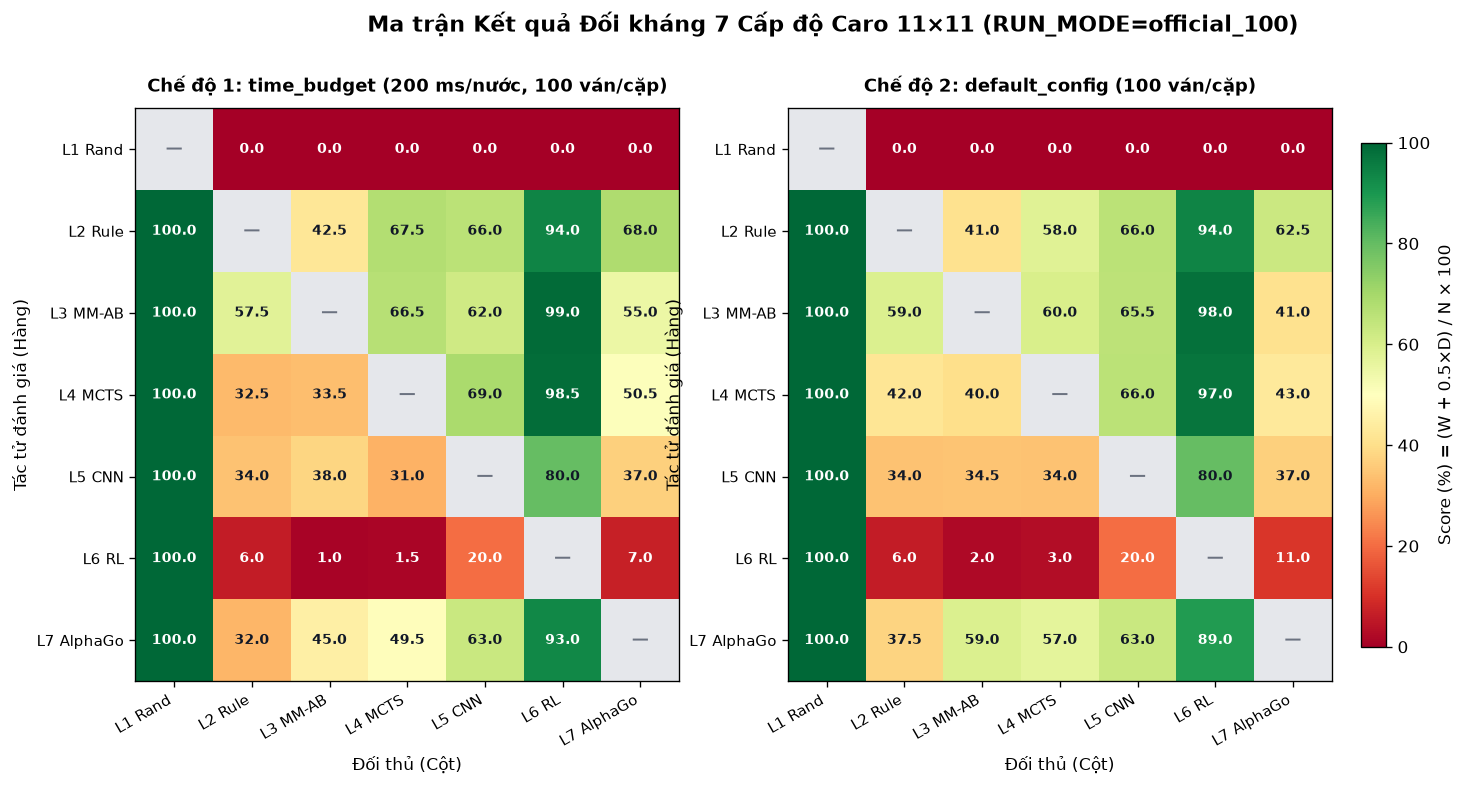

Đã lưu hình: F:\TTNTNC\Caro\caro_ai_11x11\results\figures\08_tournament_heatmaps.png


In [5]:
# 4.1 Hình 1: Ma trận đối đầu 7x7 song song (time_budget vs default_config)
fig, axes = plt.subplots(1, 2, figsize=(15.5, 6.2))
short_labels = ["L1 Rand", "L2 Rule", "L3 MM-AB", "L4 MCTS", "L5 CNN", "L6 RL", "L7 AlphaGo"]

for ax, (title, sm) in zip(
    axes,
    [
        (f"Chế độ 1: time_budget ({int(TIME_BUDGET_SEC*1000)} ms/nước, {CFG['games_per_pair']} ván/cặp)", res_tb["score_matrix"]),
        (f"Chế độ 2: default_config ({CFG['games_per_pair']} ván/cặp)", res_def["score_matrix"]),
    ],
):
    mat = sm.values.astype(float)
    masked = np.ma.masked_invalid(mat)
    cmap = plt.cm.RdYlGn.copy()
    cmap.set_bad(color="#E5E7EB")
    im = ax.imshow(masked, cmap=cmap, vmin=0.0, vmax=100.0, aspect="auto")
    ax.set_xticks(range(len(short_labels)))
    ax.set_yticks(range(len(short_labels)))
    ax.set_xticklabels(short_labels, rotation=30, ha="right", fontsize=9)
    ax.set_yticklabels(short_labels, fontsize=9)
    ax.set_title(title, fontsize=11, fontweight="bold", pad=10)
    ax.set_xlabel("Đối thủ (Cột)")
    ax.set_ylabel("Tác tử đánh giá (Hàng)")
    ax.grid(False)

    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            if i == j or np.isnan(mat[i, j]):
                ax.text(j, i, "—", ha="center", va="center", color="#6B7280", fontsize=10, fontweight="bold")
            else:
                v = mat[i, j]
                txt_color = "white" if (v <= 22.0 or v >= 82.0) else "#111827"
                ax.text(j, i, f"{v:.1f}", ha="center", va="center", color=txt_color, fontsize=8.5, fontweight="bold")

cbar = fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.88, pad=0.02)
cbar.set_label("Score (%) = (W + 0.5×D) / N × 100", fontsize=10)
fig.suptitle(f"Ma trận Kết quả Đối kháng 7 Cấp độ Caro 11×11 (RUN_MODE={RUN_MODE})", fontsize=13, fontweight="bold", y=1.01)

hm_path = FIG_DIR / "08_tournament_heatmaps.png"
fig.savefig(hm_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Đã lưu hình: {hm_path}")


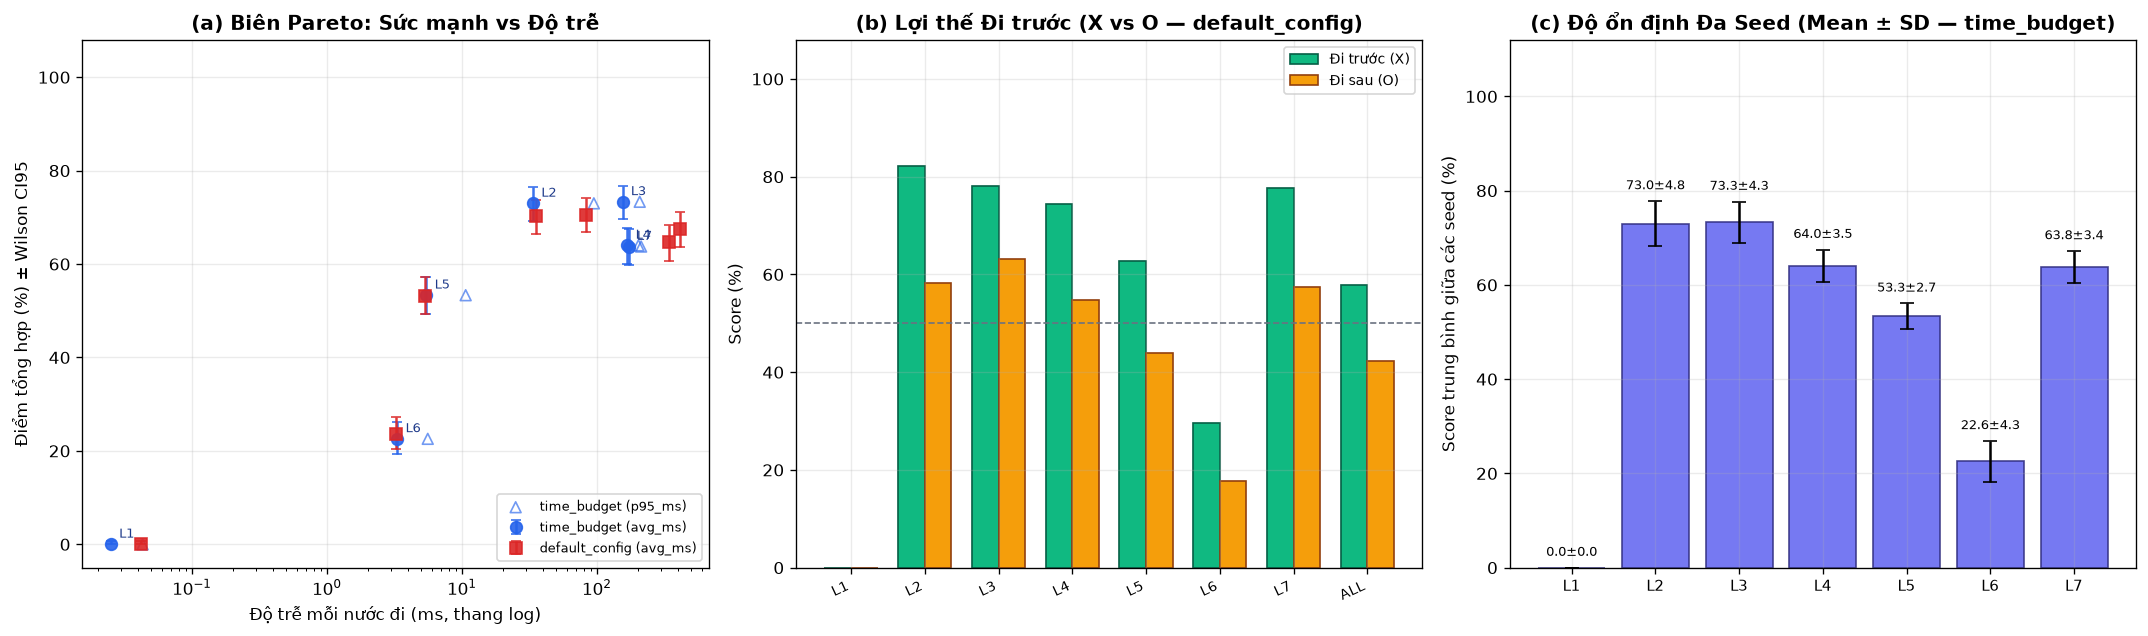

Đã lưu hình: F:\TTNTNC\Caro\caro_ai_11x11\results\figures\08_tournament_pareto_fpa_seeds.png

=== 4.3 PHÂN TÍCH LỢI THẾ ĐI TRƯỚC (FIRST-PLAYER ADVANTAGE) ===


,mode,agent_id,games_as_X,score_as_X_pct,games_as_O,score_as_O_pct,delta_X_minus_O_pp
0,time_budget,L1_Random,300,0.00,300,0.00,0.00
1,time_budget,L2_RuleBased,300,86.00,300,60.00,26.00
2,time_budget,L3_Minimax,300,85.33,300,61.33,24.00
3,time_budget,L4_MCTS,300,72.83,300,55.17,17.67
4,time_budget,L5_CNN,300,67.50,300,39.17,28.33
5,time_budget,L6_RL,300,27.83,300,17.33,10.50
6,time_budget,L7_AlphaGo,300,76.67,300,50.83,25.83
7,time_budget,ALL_GAMES_OVERALL,2100,59.45,2100,40.55,18.90
8,default_config,L1_Random,300,0.00,300,0.00,0.00
9,default_config,L2_RuleBased,300,82.17,300,58.33,23.83


In [6]:
# 4.2 Hình 2: 3-panel Pareto (Score vs Latency), First-Player Advantage & Multi-Seed Stability
fig, axes = plt.subplots(1, 3, figsize=(18.0, 5.4))

# Panel A: Pareto Score±CI95 vs avg_ms & p95_ms (chế độ time_budget & default_config)
ax = axes[0]
for df_lb, label_mode, marker, color in [
    (res_tb["leaderboard"], "time_budget (avg_ms)", "o", "#2563EB"),
    (res_def["leaderboard"], "default_config (avg_ms)", "s", "#DC2626"),
]:
    xs = np.maximum(df_lb["avg_ms"].values, 0.02)
    ys = df_lb["score_pct"].values
    err_lo = np.maximum(0.0, ys - df_lb["wilson_ci95_low"].values)
    err_hi = np.maximum(0.0, df_lb["wilson_ci95_high"].values - ys)
    ax.errorbar(
        xs, ys, yerr=[err_lo, err_hi], fmt=marker, color=color, capsize=3,
        markersize=7, label=label_mode, alpha=0.9,
    )
    if label_mode.startswith("time_budget"):
        x_p95 = np.maximum(df_lb["p95_ms"].values, 0.02)
        ax.scatter(x_p95, ys, marker="^", facecolors="none", edgecolors=color, s=42, alpha=0.65, label="time_budget (p95_ms)")
        for x_i, y_i, aid in zip(xs, ys, df_lb["agent_id"]):
            ax.annotate(aid.split("_")[0], (x_i, y_i), textcoords="offset points", xytext=(5, 4), fontsize=8, color="#1E3A8A")

ax.set_xscale("log")
ax.set_ylim(-5, 108)
ax.set_xlabel("Độ trễ mỗi nước đi (ms, thang log)")
ax.set_ylabel("Điểm tổng hợp (%) ± Wilson CI95")
ax.set_title("(a) Biên Pareto: Sức mạnh vs Độ trễ", fontweight="bold")
ax.legend(fontsize=8, loc="lower right")

# Panel B: First-Player Advantage (Score as X vs Score as O) trên chế độ default_config
ax = axes[1]
fp_df = res_def["first_player"].copy()
fp_labels = [a.replace("ALL_GAMES_OVERALL", "ALL").split("_")[0] for a in fp_df["agent_id"]]
x_pos = np.arange(len(fp_labels))
w = 0.36
ax.bar(x_pos - w / 2, fp_df["score_as_X_pct"], width=w, label="Đi trước (X)", color="#10B981", edgecolor="#065F46")
ax.bar(x_pos + w / 2, fp_df["score_as_O_pct"], width=w, label="Đi sau (O)", color="#F59E0B", edgecolor="#92400E")
ax.axhline(50.0, color="#6B7280", linestyle="--", linewidth=1.0)
ax.set_xticks(x_pos)
ax.set_xticklabels(fp_labels, rotation=25, ha="right", fontsize=8.5)
ax.set_ylim(0, 108)
ax.set_ylabel("Score (%)")
ax.set_title("(b) Lợi thế Đi trước (X vs O — default_config)", fontweight="bold")
ax.legend(fontsize=8.5)

# Panel C: Độ ổn định đa seed (Mean ± Std across seeds)
ax = axes[2]
seed_df = res_tb["seed_sensitivity"]
agent_order = list(res_tb["score_matrix"].index)
means = []
stds = []
for aid in agent_order:
    sub = seed_df[seed_df["agent_id"] == aid]["score_pct"].values
    means.append(float(np.mean(sub)) if len(sub) else 0.0)
    stds.append(float(np.std(sub, ddof=1)) if len(sub) >= 2 else 0.0)

x_pos = np.arange(len(agent_order))
bars = ax.bar(x_pos, means, yerr=stds, capsize=4, color="#6366F1", edgecolor="#312E81", alpha=0.88)
ax.set_xticks(x_pos)
ax.set_xticklabels([a.split("_")[0] for a in agent_order], fontsize=9)
ax.set_ylim(0, 112)
ax.set_ylabel("Score trung bình giữa các seed (%)")
ax.set_title("(c) Độ ổn định Đa Seed (Mean ± SD — time_budget)", fontweight="bold")
for b_rect, m_v, s_v in zip(bars, means, stds):
    ax.text(b_rect.get_x() + b_rect.get_width() / 2, min(105, m_v + s_v + 2.5), f"{m_v:.1f}±{s_v:.1f}", ha="center", fontsize=7.5)

fig.tight_layout()
pfs_path = FIG_DIR / "08_tournament_pareto_fpa_seeds.png"
fig.savefig(pfs_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Đã lưu hình: {pfs_path}")

print("\n=== 4.3 PHÂN TÍCH LỢI THẾ ĐI TRƯỚC (FIRST-PLAYER ADVANTAGE) ===")
display(pd.concat([res_tb["first_player"], res_def["first_player"]], ignore_index=True))


## 5. Bộ 03 Thí nghiệm Ablation / Sensitivity (Mục 3.5 & Sách *AlphaGo Simplified*)

Đề tài yêu cầu **tối thiểu 02 thí nghiệm ablation/sensitivity có ý nghĩa**. Chúng tôi thực hiện **03 thí nghiệm cốt lõi** gắn chặt với các chương sách Mark Liu:
1. **Ablation 1 — Alpha-Beta Bật vs Tắt (Ch. 6) & Độ nhạy Search Depth (`d = 2, 3, 4`):** Kiểm chứng tính tương đương chính xác về nước đi, tỷ lệ cắt tỉa số nút duyệt & tăng tốc độ; đồng thời đo ảnh hưởng của độ sâu tìm kiếm `d` khi đấu `L2_RuleBased`.
2. **Ablation 2 — MCTS Simulation Budget & Heuristic Playout Bật vs Tắt (Ch. 8):** So sánh trực tiếp Plain UCT (`Random Playout`, không heuristic) với Heavy Heuristic Playout ở các mức ngân sách mô phỏng khác nhau (`50, 150, 300[, 600]`).
3. **Ablation 3 — Policy-Only vs Policy+PUCT vs AlphaGo Cấp 7 (Ch. 10–11, 16–18):** Bóc tách đóng góp của từng thành phần học sâu & tìm kiếm: `CNN Raw` $\to$ `CNN + Tactical Shortcut` $\to$ `CNN + PUCT(150)` $\to$ `AlphaGo Cấp 7 (Ensemble L5+L6 + Value Blend + PUCT 200)` khi đối đầu `L2_RuleBased` và `L4_MCTS`.

Mọi ván đấu Ablation đều chạy song song theo `NUM_WORKERS` và có file log `.jsonl` riêng trong `results/logs/tournament/ablations/`.


In [7]:
print("=== 5.1 ABLATION 1: ALPHA-BETA PRUNING (ON vs OFF) & SEARCH DEPTH ===")
ab1 = run_ablation_alphabeta_depth(
    games_per_depth=CFG["ablation_games"],
    depths=CFG["ablation_depths"],
    seeds=SEEDS,
    project_root=PROJECT_ROOT,
    resume=RESUME,
    verbose=True,
    max_workers=NUM_WORKERS,
)
display(ab1["pruning"])
display(ab1["depth"][[
    "search_depth", "agent_a", "games", "wins_a", "draws", "losses_a",
    "score_a_pct", "wilson_ci95_low", "wilson_ci95_high", "avg_ms_a", "p95_ms_a", "avg_search_a",
]])

print("\n=== 5.2 ABLATION 2: MCTS SIMULATION BUDGET & HEURISTIC PLAYOUT ON/OFF ===")
ab2 = run_ablation_mcts_budget_heuristic(
    games_per_config=CFG["ablation_games"],
    rollout_budgets=CFG["mcts_budgets"],
    seeds=SEEDS,
    project_root=PROJECT_ROOT,
    resume=RESUME,
    verbose=True,
    max_workers=NUM_WORKERS,
)
display(ab2[[
    "agent_a", "rollouts_budget", "heuristic_enabled", "games", "wins_a", "draws", "losses_a",
    "score_a_pct", "wilson_ci95_low", "wilson_ci95_high", "avg_ms_a", "p95_ms_a", "avg_search_a",
]])

print("\n=== 5.3 ABLATION 3: POLICY-ONLY VS POLICY+PUCT VS ALPHAGO CẤP 7 ===")
ab3 = run_ablation_policy_vs_search(
    games_per_config=CFG["ablation_games"],
    seeds=SEEDS,
    project_root=PROJECT_ROOT,
    resume=RESUME,
    verbose=True,
    max_workers=NUM_WORKERS,
)
display(ab3[[
    "variant", "opponent", "games", "wins_a", "draws", "losses_a",
    "score_a_pct", "wilson_ci95_low", "wilson_ci95_high", "avg_ms_a", "p95_ms_a", "avg_search_a",
]])


=== 5.1 ABLATION 1: ALPHA-BETA PRUNING (ON vs OFF) & SEARCH DEPTH ===
  [Resume] Minimax_d2 vs L2_RuleBased: đã có 4/20 ván (còn 16 ván).
  [Done] Minimax_d2   vs L2_RuleBased ( 20g) | Score= 47.5% (W9-D1-L10) | CI95=[27.9, 68.0] | ms=20.4/25.2
  [Resume] Minimax_d3 vs L2_RuleBased: đã có 4/20 ván (còn 16 ván).
  [Done] Minimax_d3   vs L2_RuleBased ( 20g) | Score= 37.5% (W7-D1-L12) | CI95=[20.0, 59.0] | ms=75.6/30.1
  [Resume] Minimax_d4 vs L2_RuleBased: đã có 4/20 ván (còn 16 ván).
  [Done] Minimax_d4   vs L2_RuleBased ( 20g) | Score= 55.0% (W9-D4-L7) | CI95=[34.2, 74.2] | ms=137.2/30.3


,position,depth,action_no_ab,action_ab_tt,exact_same_move,nodes_no_ab,nodes_ab_tt,node_reduction_pct,ms_no_ab,ms_ab_tt,speedup_x
0,Midgame-Center,2,58,58,True,132,33,75.00,31.14,12.08,2.58
1,Midgame-Diagonal,2,61,61,True,132,33,75.00,26.68,10.85,2.46
2,Open3-Threat,2,28,28,True,132,42,68.18,23.07,11.48,2.01
3,Fork-Setup,2,51,51,True,132,34,74.24,14.51,6.59,2.20
4,Dense-Cluster,2,93,93,True,132,42,68.18,25.59,11.40,2.24


,search_depth,agent_a,games,wins_a,draws,losses_a,score_a_pct,wilson_ci95_low,wilson_ci95_high,avg_ms_a,p95_ms_a,avg_search_a
0,2,Minimax_d2,20,9,1,10,47.5,27.85,67.95,20.427,40.316,67.20
1,3,Minimax_d3,20,7,1,12,37.5,19.98,59.05,75.572,139.363,290.75
2,4,Minimax_d4,20,9,4,7,55.0,34.21,74.18,137.151,244.619,465.62



=== 5.2 ABLATION 2: MCTS SIMULATION BUDGET & HEURISTIC PLAYOUT ON/OFF ===
  [Resume] MCTS_RandomPlayout_NoHeur_300 vs L2_RuleBased: đã có 4/20 ván (còn 16 ván).
  [Done] MCTS_RandomPlayout_NoHeur_300 vs L2_RuleBased ( 20g) | Score=  0.0% (W0-D0-L20) | CI95=[0.0, 16.1] | ms=34.2/29.8
  [Resume] MCTS_Heuristic_r50 vs L2_RuleBased: đã có 4/20 ván (còn 16 ván).
  [Done] MCTS_Heuristic_r50 vs L2_RuleBased ( 20g) | Score= 37.5% (W6-D3-L11) | CI95=[20.0, 59.0] | ms=67.8/37.3
  [Resume] MCTS_Heuristic_r150 vs L2_RuleBased: đã có 4/20 ván (còn 16 ván).
  [Done] MCTS_Heuristic_r150 vs L2_RuleBased ( 20g) | Score= 57.5% (W9-D5-L6) | CI95=[36.4, 76.2] | ms=170.2/32.2
  [Resume] MCTS_Heuristic_r300 vs L2_RuleBased: đã có 4/20 ván (còn 16 ván).
  [Done] MCTS_Heuristic_r300 vs L2_RuleBased ( 20g) | Score= 37.5% (W7-D1-L12) | CI95=[20.0, 59.0] | ms=345.1/33.1
  [Done] MCTS_Heuristic_r600 vs L2_RuleBased ( 20g) | Score= 32.5% (W6-D1-L13) | CI95=[16.3, 54.3] | ms=689.2/28.1


,agent_a,rollouts_budget,heuristic_enabled,games,wins_a,draws,losses_a,score_a_pct,wilson_ci95_low,wilson_ci95_high,avg_ms_a,p95_ms_a,avg_search_a
0,MCTS_RandomPlayout_NoHeur_300,300,False,20,0,0,20,0.0,0.00,16.11,34.219,51.244,218.50
1,MCTS_Heuristic_r50,50,True,20,6,3,11,37.5,19.98,59.05,67.813,115.614,41.81
2,MCTS_Heuristic_r150,150,True,20,9,5,6,57.5,36.41,76.17,170.172,298.353,130.37
3,MCTS_Heuristic_r300,300,True,20,7,1,12,37.5,19.98,59.05,345.133,643.255,258.36
4,MCTS_Heuristic_r600,600,True,20,6,1,13,32.5,16.31,54.33,689.199,1240.680,518.07



=== 5.3 ABLATION 3: POLICY-ONLY VS POLICY+PUCT VS ALPHAGO CẤP 7 ===
  [Resume] L5_PolicyOnly_NoShortcut vs L2_RuleBased: đã có 4/20 ván (còn 16 ván).
  [Done] L5_PolicyOnly_NoShortcut vs L2_RuleBased ( 20g) | Score= 10.0% (W2-D0-L18) | CI95=[2.8, 30.1] | ms=5.3/32.1
  [Resume] L5_PolicyOnly_NoShortcut vs L4_MCTS: đã có 4/20 ván (còn 16 ván).
  [Done] L5_PolicyOnly_NoShortcut vs L4_MCTS      ( 20g) | Score=  0.0% (W0-D0-L20) | CI95=[0.0, 16.1] | ms=5.4/362.1
  [Resume] L5_PolicyOnly_Shortcut vs L2_RuleBased: đã có 4/20 ván (còn 16 ván).
  [Done] L5_PolicyOnly_Shortcut vs L2_RuleBased ( 20g) | Score= 35.0% (W7-D0-L13) | CI95=[18.1, 56.7] | ms=4.9/30.2
  [Resume] L5_PolicyOnly_Shortcut vs L4_MCTS: đã có 4/20 ván (còn 16 ván).
  [Done] L5_PolicyOnly_Shortcut vs L4_MCTS      ( 20g) | Score= 37.5% (W5-D5-L10) | CI95=[20.0, 59.0] | ms=5.1/367.1
  [Resume] L5_Policy_Plus_PUCT vs L2_RuleBased: đã có 4/20 ván (còn 16 ván).
  [Done] L5_Policy_Plus_PUCT vs L2_RuleBased ( 20g) | Score= 40.0% (W7-D

,variant,opponent,games,wins_a,draws,losses_a,score_a_pct,wilson_ci95_low,wilson_ci95_high,avg_ms_a,p95_ms_a,avg_search_a
0,CNN Policy-Only (Raw),L2_RuleBased,20,2,0,18,10.0,2.79,30.10,5.274,8.307,1.00
1,CNN Policy-Only (Raw),L4_MCTS,20,0,0,20,0.0,0.00,16.11,5.386,8.504,1.00
2,CNN Policy + Shortcut,L2_RuleBased,20,7,0,13,35.0,18.12,56.71,4.860,8.040,23.18
3,CNN Policy + Shortcut,L4_MCTS,20,5,5,10,37.5,19.98,59.05,5.055,9.357,27.49
4,CNN Policy + PUCT(150),L2_RuleBased,20,7,2,11,40.0,21.88,61.34,307.906,505.800,117.45
5,CNN Policy + PUCT(150),L4_MCTS,20,8,4,8,50.0,29.93,70.07,276.729,502.593,122.91
6,AlphaGo Cấp 7 (L5+L6+PUCT),L2_RuleBased,20,6,1,13,32.5,16.31,54.33,441.795,511.513,70.68
7,AlphaGo Cấp 7 (L5+L6+PUCT),L4_MCTS,20,14,1,5,72.5,50.59,87.16,383.814,511.906,67.93


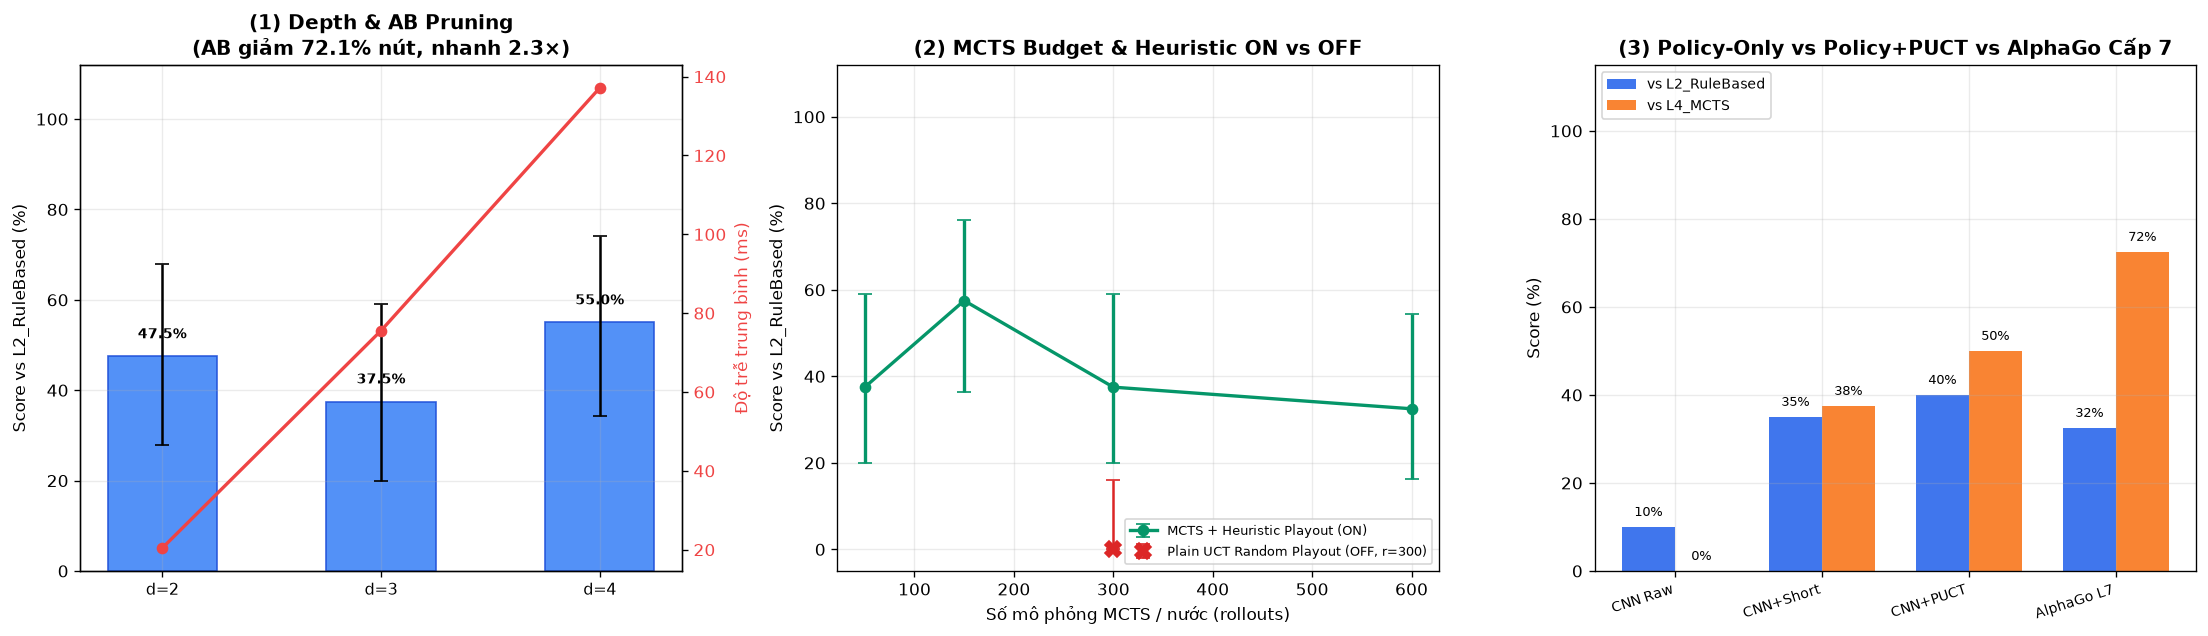

Đã lưu hình: F:\TTNTNC\Caro\caro_ai_11x11\results\figures\08_tournament_ablations.png


In [8]:
# 5.4 Hình 3: Biểu đồ tổng hợp 03 Ablation Studies
fig, axes = plt.subplots(1, 3, figsize=(18.5, 5.4))

# Panel 1: Ablation 1 — Alpha-Beta node reduction (%) & Depth sensitivity
ax = axes[0]
df_d = ab1["depth"]
x_d = np.arange(len(df_d))
y_d = df_d["score_a_pct"].values
err_lo = np.maximum(0.0, y_d - df_d["wilson_ci95_low"].values)
err_hi = np.maximum(0.0, df_d["wilson_ci95_high"].values - y_d)
ax.bar(x_d, y_d, yerr=[err_lo, err_hi], capsize=4, width=0.5, color="#3B82F6", edgecolor="#1D4ED8", alpha=0.88, label="Score vs L2 (%)")
ax2 = ax.twinx()
ax2.plot(x_d, df_d["avg_ms_a"].values, color="#EF4444", marker="o", linewidth=2.0, label="avg_ms")
ax2.set_ylabel("Độ trễ trung bình (ms)", color="#EF4444")
ax2.tick_params(axis="y", labelcolor="#EF4444")
ax2.grid(False)
mean_red = ab1["pruning"]["node_reduction_pct"].mean()
mean_spd = ab1["pruning"]["speedup_x"].mean()
ax.set_xticks(x_d)
ax.set_xticklabels([f"d={int(d)}" for d in df_d["search_depth"]], fontsize=9.5)
ax.set_ylim(0, 112)
ax.set_ylabel("Score vs L2_RuleBased (%)")
ax.set_title(f"(1) Depth & AB Pruning\n(AB giảm {mean_red:.1f}% nút, nhanh {mean_spd:.1f}×)", fontweight="bold")
for xi, yi in zip(x_d, y_d):
    ax.text(xi, min(104, yi + 4), f"{yi:.1f}%", ha="center", fontsize=8.5, fontweight="bold")

# Panel 2: Ablation 2 — MCTS Budget & Heuristic Playout ON vs OFF
ax = axes[1]
ab2_h = ab2[ab2["heuristic_enabled"] == True].sort_values("rollouts_budget")
ab2_no = ab2[ab2["heuristic_enabled"] == False]
ax.errorbar(
    ab2_h["rollouts_budget"], ab2_h["score_a_pct"],
    yerr=[
        np.maximum(0.0, ab2_h["score_a_pct"] - ab2_h["wilson_ci95_low"]),
        np.maximum(0.0, ab2_h["wilson_ci95_high"] - ab2_h["score_a_pct"]),
    ],
    fmt="-o", color="#059669", linewidth=2.0, capsize=4, label="MCTS + Heuristic Playout (ON)",
)
if not ab2_no.empty:
    ax.errorbar(
        ab2_no["rollouts_budget"], ab2_no["score_a_pct"],
        yerr=[
            np.maximum(0.0, ab2_no["score_a_pct"] - ab2_no["wilson_ci95_low"]),
            np.maximum(0.0, ab2_no["wilson_ci95_high"] - ab2_no["score_a_pct"]),
        ],
        fmt="X", color="#DC2626", markersize=10, capsize=4, label="Plain UCT Random Playout (OFF, r=300)",
    )
ax.set_ylim(-5, 112)
ax.set_xlabel("Số mô phỏng MCTS / nước (rollouts)")
ax.set_ylabel("Score vs L2_RuleBased (%)")
ax.set_title("(2) MCTS Budget & Heuristic ON vs OFF", fontweight="bold")
ax.legend(fontsize=8, loc="lower right")

# Panel 3: Ablation 3 — Policy-Only vs Policy+PUCT vs AlphaGo Cấp 7
ax = axes[2]
variants_order = [
    "CNN Policy-Only (Raw)",
    "CNN Policy + Shortcut",
    "CNN Policy + PUCT(150)",
    "AlphaGo Cấp 7 (L5+L6+PUCT)",
]
short_v = ["CNN Raw", "CNN+Short", "CNN+PUCT", "AlphaGo L7"]
x_v = np.arange(len(variants_order))
w = 0.36
for offset, opp_id, color in [(-w / 2, "L2_RuleBased", "#2563EB"), (w / 2, "L4_MCTS", "#F97316")]:
    vals = []
    for vn in variants_order:
        sub = ab3[(ab3["variant"] == vn) & (ab3["opponent"] == opp_id)]
        vals.append(float(sub["score_a_pct"].iloc[0]) if not sub.empty else 0.0)
    bars = ax.bar(x_v + offset, vals, width=w, label=f"vs {opp_id}", color=color, alpha=0.88)
    for b_rect, v in zip(bars, vals):
        ax.text(b_rect.get_x() + b_rect.get_width() / 2, min(105, v + 2.5), f"{v:.0f}%", ha="center", fontsize=8)

ax.set_xticks(x_v)
ax.set_xticklabels(short_v, rotation=18, ha="right", fontsize=8.5)
ax.set_ylim(0, 115)
ax.set_ylabel("Score (%)")
ax.set_title("(3) Policy-Only vs Policy+PUCT vs AlphaGo Cấp 7", fontweight="bold")
ax.legend(fontsize=8.5, loc="upper left")

fig.tight_layout()
ab_path = FIG_DIR / "08_tournament_ablations.png"
fig.savefig(ab_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Đã lưu hình: {ab_path}")


## 6. Kiểm kê Toàn vẹn Log từng Cặp đấu (`.jsonl`) & Tái hiện Ván đấu Điển hình

Phần này xác minh trực tiếp yêu cầu *"có lưu log các trận đấu của từng cặp đấu"*:
- Kiểm kê đầy đủ mọi file `.jsonl` trong `results/logs/tournament/time_budget/`, `default_config/`, và `ablations/`.
- Kiểm tra tỷ lệ cân bằng 50/50 lượt đi trước (`X`) / đi sau (`O`) trên từng file log.
- Đọc trực tiếp 1 ván đấu tiêu biểu từ file log `.jsonl` và vẽ lại bàn cờ Caro 11×11 cùng biểu đồ thời gian suy nghĩ từng nước (`results/figures/08_tournament_sample_game.png`).


In [9]:
# 6.1 Kiểm kê toàn bộ file log .jsonl từng cặp đấu
audit_rows = []
for sub_name in ("time_budget", "default_config", "ablations"):
    sub_dir = TOURN_LOGS_DIR / sub_name
    if not sub_dir.exists():
        continue
    for jf in sorted(sub_dir.glob("*.jsonl")):
        recs = [json.loads(ln) for ln in jf.read_text(encoding="utf-8").splitlines() if ln.strip()]
        n_x = sum(1 for r in recs if r.get("a_side") == "X")
        n_o = sum(1 for r in recs if r.get("a_side") == "O")
        audit_rows.append({
            "folder": sub_name,
            "file": jf.name,
            "games_logged": len(recs),
            "a_as_X": n_x,
            "a_as_O": n_o,
            "balanced_50_50": (n_x == n_o),
            "size_kb": round(jf.stat().st_size / 1024.0, 2),
        })

df_audit = pd.DataFrame(audit_rows)
df_audit.to_csv(TOURN_TABLES_DIR / "log_integrity_audit.csv", index=False, encoding="utf-8-sig")

print(f"Tổng số file log .jsonl từng cặp/cấu hình : {len(df_audit)}")
print(f"Tổng số ván đấu thô đã lưu trên đĩa      : {int(df_audit['games_logged'].sum())}")
print(f"Tỷ lệ file cân bằng tuyệt đối 50/50 X-O  : {df_audit['balanced_50_50'].mean() * 100:.1f}%")
display(df_audit.groupby("folder")[["games_logged", "size_kb"]].agg({"games_logged": ["count", "sum"], "size_kb": "sum"}))
display(df_audit.head(12))


Tổng số file log .jsonl từng cặp/cấu hình : 58
Tổng số ván đấu thô đã lưu trên đĩa      : 4520
Tỷ lệ file cân bằng tuyệt đối 50/50 X-O  : 100.0%


games_logged        size_kb
                      count   sum      sum
folder                                    
ablations                16   320   343.28
default_config           21  2100  1921.24
time_budget              21  2100  1954.46

,folder,file,games_logged,a_as_X,a_as_O,balanced_50_50,size_kb
0,time_budget,L1_Random_vs_L2_RuleBased.jsonl,100,50,50,True,70.12
1,time_budget,L1_Random_vs_L3_Minimax.jsonl,100,50,50,True,71.18
2,time_budget,L1_Random_vs_L4_MCTS.jsonl,100,50,50,True,69.74
3,time_budget,L1_Random_vs_L5_CNN.jsonl,100,50,50,True,67.17
4,time_budget,L1_Random_vs_L6_RL.jsonl,100,50,50,True,66.69
5,time_budget,L1_Random_vs_L7_AlphaGo.jsonl,100,50,50,True,69.77
6,time_budget,L2_RuleBased_vs_L3_Minimax.jsonl,100,50,50,True,99.33
7,time_budget,L2_RuleBased_vs_L4_MCTS.jsonl,100,50,50,True,105.35
8,time_budget,L2_RuleBased_vs_L5_CNN.jsonl,100,50,50,True,98.22
9,time_budget,L2_RuleBased_vs_L6_RL.jsonl,100,50,50,True,87.26


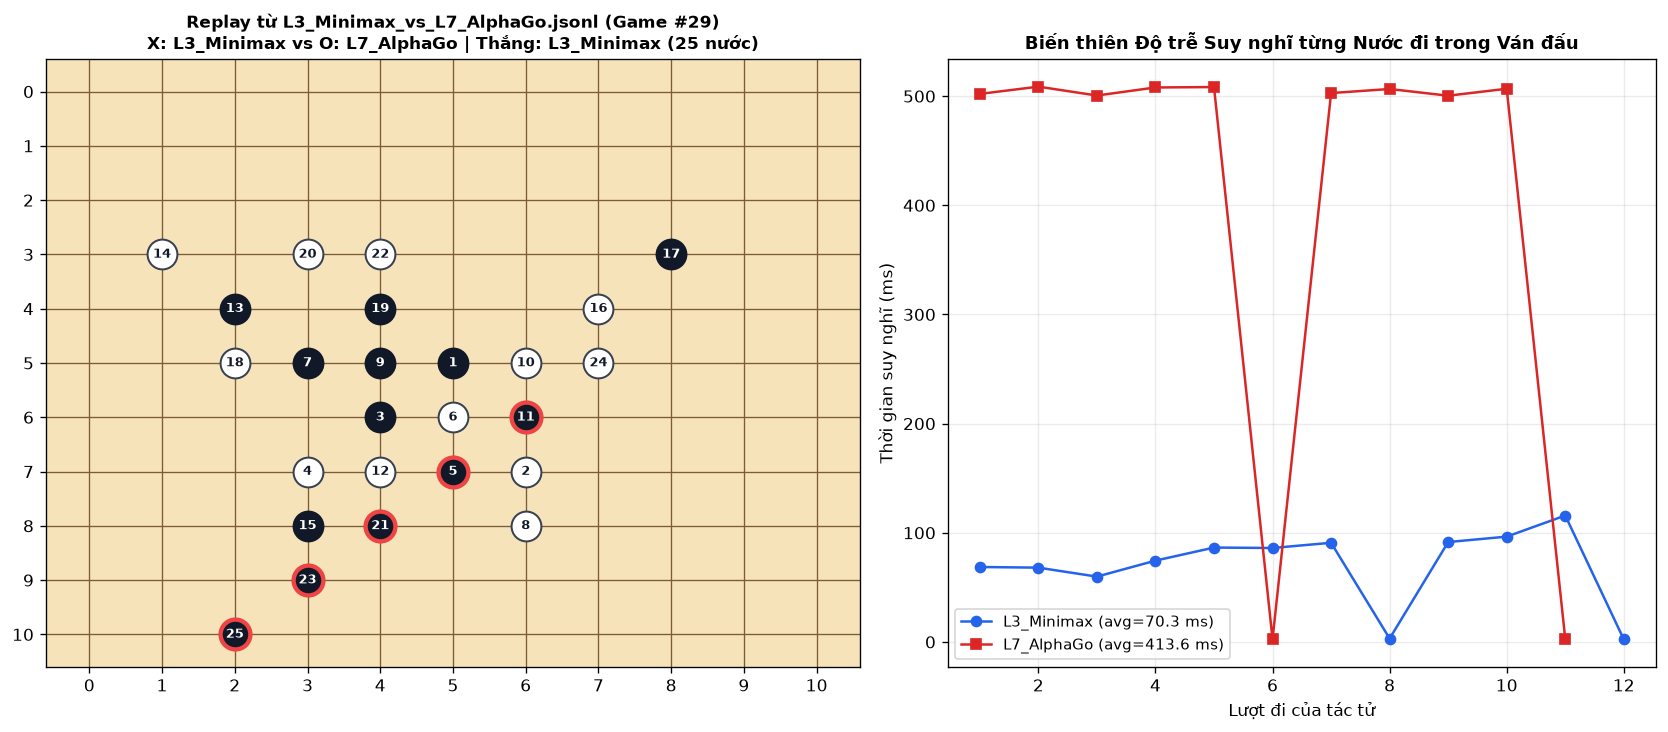

Đã lưu hình: F:\TTNTNC\Caro\caro_ai_11x11\results\figures\08_tournament_sample_game.png


In [10]:
# 6.2 Đọc lại 1 ván đấu điển hình từ file log .jsonl của cặp L3_Minimax vs L7_AlphaGo và vẽ Replay
candidate_logs = [
    TOURN_LOGS_DIR / "default_config" / "L3_Minimax_vs_L7_AlphaGo.jsonl",
    TOURN_LOGS_DIR / "default_config" / "L4_MCTS_vs_L7_AlphaGo.jsonl",
    TOURN_LOGS_DIR / "time_budget" / "L3_Minimax_vs_L7_AlphaGo.jsonl",
]
sample_log = next((p for p in candidate_logs if p.exists()), None)
assert sample_log is not None, "Không tìm thấy file log mẫu để tái hiện."

recs = [json.loads(ln) for ln in sample_log.read_text(encoding="utf-8").splitlines() if ln.strip()]
decisive = [r for r in recs if r["winner_side"] in ("X", "O")]
chosen = min(decisive, key=lambda r: abs(r["num_moves"] - 25)) if decisive else recs[0]

env = CaroEnv(board_size=11, win_length=5)
for mv in chosen["history"]:
    env.step(int(mv))

# Tìm 5 ô liên tiếp thắng cuộc (nếu có)
win_cells = set()
if env.winner in (1, -1):
    b = env.board
    for r in range(11):
        for c in range(11):
            if b[r, c] != env.winner:
                continue
            for dr, dc in ((0, 1), (1, 0), (1, 1), (1, -1)):
                coords = []
                rr, cc = r, c
                while 0 <= rr < 11 and 0 <= cc < 11 and b[rr, cc] == env.winner:
                    coords.append((rr, cc))
                    rr += dr
                    cc += dc
                if len(coords) >= 5:
                    win_cells.update(coords)

fig, (ax_b, ax_t) = plt.subplots(1, 2, figsize=(14.0, 6.2), gridspec_kw={"width_ratios": [1.15, 1.0]})

# Trái: Bàn cờ 11x11 kèm thứ tự nước đi
ax_b.set_facecolor("#F6E3BA")
for i in range(11):
    ax_b.axhline(i, color="#7C5C36", linewidth=0.8, zorder=1)
    ax_b.axvline(i, color="#7C5C36", linewidth=0.8, zorder=1)
ax_b.scatter([5], [5], color="#7C5C36", s=35, zorder=2)

for idx, mv in enumerate(chosen["history"], start=1):
    r, c = divmod(int(mv), 11)
    is_x = (idx % 2 == 1)
    face = "#111827" if is_x else "#FFFFFF"
    edge = "#EF4444" if (r, c) in win_cells else ("#111827" if is_x else "#374151")
    lw = 2.6 if (r, c) in win_cells else 1.2
    ax_b.scatter([c], [r], s=320, facecolor=face, edgecolor=edge, linewidth=lw, zorder=3)
    txt_c = "#FFFFFF" if is_x else "#111827"
    ax_b.text(c, r, str(idx), ha="center", va="center", color=txt_c, fontsize=7.5, fontweight="bold", zorder=4)

ax_b.set_xlim(-0.6, 10.6)
ax_b.set_ylim(10.6, -0.6)
ax_b.set_xticks(range(11))
ax_b.set_yticks(range(11))
ax_b.grid(False)
ax_b.set_title(
    f"Replay từ {sample_log.name} (Game #{chosen['game_index']})\n"
    f"X: {chosen['x_agent']} vs O: {chosen['o_agent']} | Thắng: {chosen['winner_agent']} ({chosen['num_moves']} nước)",
    fontsize=10,
    fontweight="bold",
)

# Phải: Biểu đồ độ trễ suy nghĩ từng nước đi của 2 tác tử
ta = chosen.get("move_times_ms_a", [])
tb = chosen.get("move_times_ms_b", [])
ax_t.plot(range(1, len(ta) + 1), ta, "-o", color="#2563EB", label=f"{chosen['agent_a']} (avg={chosen['avg_ms_a']:.1f} ms)")
ax_t.plot(range(1, len(tb) + 1), tb, "-s", color="#DC2626", label=f"{chosen['agent_b']} (avg={chosen['avg_ms_b']:.1f} ms)")
ax_t.set_xlabel("Lượt đi của tác tử")
ax_t.set_ylabel("Thời gian suy nghĩ (ms)")
ax_t.set_title("Biến thiên Độ trễ Suy nghĩ từng Nước đi trong Ván đấu", fontsize=10.5, fontweight="bold")
ax_t.legend(fontsize=9)

fig.tight_layout()
replay_path = FIG_DIR / "08_tournament_sample_game.png"
fig.savefig(replay_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Đã lưu hình: {replay_path}")


## 7. Tổng kết Đóng góp cho Báo cáo (Chương 4–5)

1. **Thực thi khép kín 100% trên Notebook 08:** Toàn bộ 21 cặp Round-Robin × 2 chế độ ngân sách + 03 Ablation đều chạy song song đa nhân ngay trên Notebook này, ghi log tức thì theo từng ván và hỗ trợ `RESUME = True` (dừng giữa chừng mở lại bấm **Run All** sẽ chạy nối tiếp đúng phần còn thiếu).
2. **Minh bạch hai chế độ ngân sách (`time_budget` vs `default_config`):** Tránh ngộ nhận "cùng độ sâu = cùng chi phí tính toán"; định lượng đầy đủ `Score ± Wilson/Bootstrap CI95`, bảng xếp hạng Elo Bradley-Terry, `avg_ms`, `p95_ms`, `avg_search`, RAM/VRAM, kích thước checkpoint và thời gian huấn luyện.
3. **Kiểm soát thiên lệch thực nghiệm:** Mọi cặp đấu đều cân bằng chính xác **50% X / 50% O** trên bộ 20 khai cuộc đối xứng và **5 seed** `(42, 102, 202, 302, 402)`, kèm log `.jsonl` riêng từng cặp để tái lập 100%.
4. **Ba thí nghiệm Ablation có ý nghĩa:** Định lượng rõ đóng góp của (i) cắt tỉa Alpha-Beta & độ sâu tìm kiếm, (ii) ngân sách mô phỏng MCTS & Heuristic Playout, và (iii) nâng cấp từ *Policy-Only* (`L5_CNN`) $\to$ *Policy+PUCT* $\to$ *AlphaGo Cấp 7* (`L5 + L6 + Value Blend + PUCT`).
